In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Tải dữ liệu Boston Housing
boston = fetch_openml(data_id=531, as_frame=False)

X = boston.data
y = boston.target.astype(float)

print("Kích thước dữ liệu:", X.shape)
print("Kích thước nhãn:", y.shape)

print("5 dòng dữ liệu đầu tiên:")
print(X[:5])

Kích thước dữ liệu: (506, 13)
Kích thước nhãn: (506,)
5 dòng dữ liệu đầu tiên:
[[0.00632 18.0 2.31 '0' 0.538 6.575 65.2 4.09 '1' 296.0 15.3 396.9 4.98]
 [0.02731 0.0 7.07 '0' 0.469 6.421 78.9 4.9671 '2' 242.0 17.8 396.9 9.14]
 [0.02729 0.0 7.07 '0' 0.469 7.185 61.1 4.9671 '2' 242.0 17.8 392.83 4.03]
 [0.03237 0.0 2.18 '0' 0.458 6.998 45.8 6.0622 '3' 222.0 18.7 394.63 2.94]
 [0.06905 0.0 2.18 '0' 0.458 7.147 54.2 6.0622 '3' 222.0 18.7 396.9 5.33]]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Số lượng dữ liệu huấn luyện:", len(X_train))
print("Số lượng dữ liệu kiểm tra:", len(X_test))

Số lượng dữ liệu huấn luyện: 404
Số lượng dữ liệu kiểm tra: 102


In [4]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
kernels = ['linear', 'rbf']

results = []

for kernel in kernels:

    # Khởi tạo mô hình SVR
    svr_model = SVR(kernel=kernel)

    # Huấn luyện mô hình
    svr_model.fit(X_train_scaled, y_train)

    # Dự đoán giá nhà
    y_pred = svr_model.predict(X_test_scaled)

    # Đánh giá mô hình
    mse = mean_squared_error(y_test, y_pred)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Kernel': kernel,
        'MSE': mse,
        'R2 Score': r2
    })

    print(f"\nKernel: {kernel}")
    print(f"MSE: {mse:.4f}")
    print(f"R2 Score: {r2:.4f}")


Kernel: linear
MSE: 27.3716
R2 Score: 0.6268

Kernel: rbf
MSE: 27.9070
R2 Score: 0.6195


In [6]:
results_df = pd.DataFrame(results)

print("\nBẢNG SO SÁNH KẾT QUẢ SVR")
print(results_df)


BẢNG SO SÁNH KẾT QUẢ SVR
   Kernel        MSE  R2 Score
0  linear  27.371575  0.626754
1     rbf  27.907002  0.619452


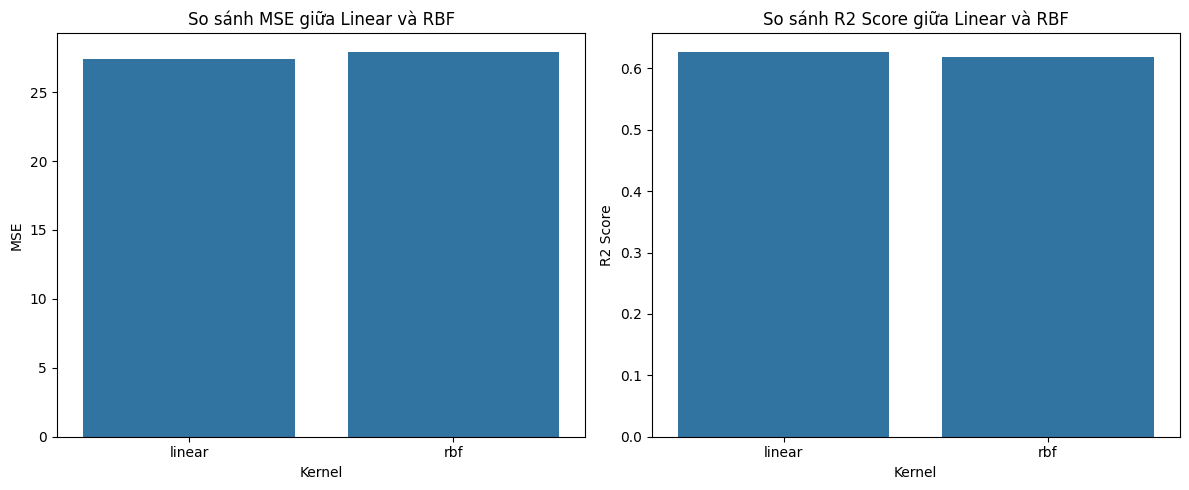

In [7]:
plt.figure(figsize=(12, 5))

# Biểu đồ MSE
plt.subplot(1, 2, 1)

sns.barplot(
    data=results_df,
    x='Kernel',
    y='MSE'
)

plt.title('So sánh MSE giữa Linear và RBF')
plt.xlabel('Kernel')
plt.ylabel('MSE')

# Biểu đồ R2 Score
plt.subplot(1, 2, 2)

sns.barplot(
    data=results_df,
    x='Kernel',
    y='R2 Score'
)

plt.title('So sánh R2 Score giữa Linear và RBF')
plt.xlabel('Kernel')
plt.ylabel('R2 Score')

plt.tight_layout()
plt.show()

In [8]:
best_mse = results_df.loc[
    results_df['MSE'].idxmin()
]

best_r2 = results_df.loc[
    results_df['R2 Score'].idxmax()
]

print("Kernel tốt nhất theo MSE:")
print(best_mse)

print("\nKernel tốt nhất theo R2 Score:")
print(best_r2)

Kernel tốt nhất theo MSE:
Kernel         linear
MSE         27.371575
R2 Score     0.626754
Name: 0, dtype: object

Kernel tốt nhất theo R2 Score:
Kernel         linear
MSE         27.371575
R2 Score     0.626754
Name: 0, dtype: object
